# **Creation of a Robo Advisor for Personal Finance Management, with Optimization of Expense Items and Efficient Allocation of Savings through Updated Financial Market Data**

---

The project aims to develop an intelligent virtual assistant for personal finance management, capable of **accompanying the user throughout the entire economic management cycle**: from **budget monitoring** to the detection of savings and deficits, up to the generation of strategic analyses useful to **optimize expenses** and **deploy savings** effectively.

The architecture is based on **LangGraph**, a technology that allows modeling the system as a decision graph of agents and tools. This approach enables flexible and modular management of interactions, maintaining context memory and past user requests thanks to integration with advanced NLP (Natural Language Processing) models.

**Interaction Flow**

1. **User input:** the assistant receives a file containing the income and expense items related to a personal financial budget. Based on this data, it can handle textual requests such as: "Show me the monthly totals," "Show me the deficit items," "How much can I save on average each month?". By downloading real-time data from the market, it can finally answer the question: "Suggest an optimized investment portfolio."
   
2. **Agent decision:** a decision node interprets the query and selects the most suitable task to activate within the graph. Each task is represented as a specialized node.

3. **Task execution:** main tasks:
   
   - **Task 1 - Monthly cash flow analysis:** calculates and displays income, expenses, and monthly balance, highlighting any deficit periods.
   
   - **Task 2 - Expense analysis in losing months:** for months with a negative balance, identifies the most critical spending categories and suggests optimization areas.
   
   - **Task 3 - Average monthly savings analysis:** estimates how much the user can save on average each month based on historical balance.
   
   - **Task 4 - Suggests a simple, efficient Portfolio** for **savings management**, based on **historical stock price data** and selecting the **best portfolio option** with assets and percentage weights, performing 5000 **Monte Carlo simulations** and identifying the best portfolio based on **expected return**, **volatility**, **internal portfolio covariance analysis**, and **Sharpe ratio**.

4. In particular, the combination of the **Efficient Portfolio** was reached through:

  I. **Financial asset analysis (stocks and ETF shares):** in the initial phase, some **assets segmented by classes** (safe havens, technology, large cap, global indices) are selected. The **distribution of historical price series** is analyzed and the presence of **kurtosis** is detected. Then **future returns** are estimated using the **bootstrap techniqu**e, which consists of **sampling daily returns** to limit the influence of extreme events highlighted by kurtosis. A **simulation of the return for the following year** is then carried out based on the sampling.

  II. **Identification of a simple, efficient Portfolio:** **Expected returns** are estimated based on the average returns and **annualized volatility** of historical price series. The **covariance matrix** among assets is also calculated, which is essential for capturing **shared risk relationships**. Using these inputs, a **Monte Carlo simulation** is performed, generating 50,000 portfolios with random asset weights. For each portfolio, the **Sharpe ratio** is computed to measure the **risk-adjusted return**. Finally, the portfolio corresponding to the **maximum Sharpe ratio** is identified as **the optimal efficient portfolio**, representing the best risk-return balance.

5. **Structured and personalized output:** the agent provides a response consistent with the request, including analytical data and targeted suggestions. Thanks to the modular architecture, the system is also easily extendable and can adapt to integrative scenarios in a scalable and coherent way.

**CONCLUSIONS**: The project highlights the effectiveness of **agent-based artificial intelligence** for **personal finance management**, offering timely and reliable answers to simple questions related to **financial monitoring**, while supporting complex and multi-level activities, such as decisions regarding **planning the employment of savings**. The assistant thus configures itself as an **advanced support tool** in a **broad, structured, and multi-level perspective**.



> ***Methodological note on Expected Returns***:
> - In the phase of **simulating future returns for individual assets**, **bootstrapping of daily returns** was used to better reflect the empirical distribution of returns, mitigating the impact of outliers and high kurtosis.
> - However, in constructing the **efficient portfolio** according to the mean-variance approach, the expected return was estimated as the **historical mean of returns**, consistent with Markowitz’s classical theory, where it is assumed that historical statistics (mean and covariance) represent future expectations.


In [ ]:
!pip install -U langchain langsmith langgraph python-dotenv

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.0/363.0 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 152.4/152.4 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.2/44.2 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.5/216.5 kB 16.7 MB/s eta 0:00:00
  Attempting uninstall: langsmith
    Found existing installation: langsmith 0.3.44
    Uninstalling langsmith-0.3.44:
      Successfully uninstalled langsmith-0.3.44


In [ ]:
# Libraries

import pandas as pd
import numpy as np

from langchain_core.messages import HumanMessage
from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, StateGraph, MessagesState
from langgraph.prebuilt import ToolNode
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

Loading the dataset

In [ ]:
df = "https://raw.githubusercontent.com/Valeria-Raele/agentic_robot_advisor/refs/heads/main/dataset/Personal_transactions_2024_2025.csv"
df = pd.read_csv(df, index_col=0)

df.head(15)

,Description,Amount,Transaction Type,Category,Account Name
Date,,,,,
01/01/2024,Amazon,"11,11",debit,Shopping,Platinum Card
01/02/2024,Mortgage Payment,"1247,44",debit,Mortgage & Rent,Checking
01/02/2024,Thai Restaurant,"24,22",debit,Restaurants,Silver Card
01/03/2024,Credit Card Payment,"2298,09",credit,Credit Card Payment,Platinum Card
01/04/2024,Netflix,"11,76",debit,Movies & DVDs,Platinum Card
01/05/2024,American Tavern,"25,85",debit,Restaurants,Silver Card
01/06/2024,Hardware Store,"18,45",debit,Home Improvement,Silver Card
01/08/2024,Gas Company,45,debit,Utilities,Checking
01/08/2024,Hardware Store,"15,38",debit,Home Improvement,Silver Card


Dataset preparation

In [ ]:
# Check for null or missing values per column
missing_values = df.isnull().sum()

print("Null or missing values per column:")
print(missing_values)

Null or missing values per column:
Description         0
Amount              0
Transaction Type    0
Category            0
Account Name        0
dtype: int64


Building Tools and Agent with LangGraph

In [ ]:
# Initialize DataFrame and global variable
df.index = pd.to_datetime(df.index, format="%m/%d/%Y")
df["Amount"] = df["Amount"].astype(str).str.replace(",", ".").astype(float)
df["Month"] = df.index.to_period("M").to_timestamp()
deficit_months = []

Define the Tasks:
- Task 1: Financial analysis and savings generation
- Task 2: Analysis of the main expense categories in deficit months.

In [ ]:
@tool
def analyze_finance(query: str) -> str:
    """
    Analyzes personal finances on demand.

    Supports:
    - 'monthly totals': calculates income, expenses, and monthly balance.
    - 'top 3': returns the top 3 entries by transaction type.
    - 'savings' or 'mean': calculates the average monthly savings.

    Args:
        query (str): User's question.

    Returns:
        str: Result of the requested analysis, which may be a summary of monthly totals,
             the top 3 transactions, or the average savings calculation.
    """
    query_lower = query.lower()

    if "monthly totals" in query_lower:
        monthly_summary = df.groupby(["Month", "Transaction Type"])["Amount"].sum().unstack().fillna(0)
        monthly_summary["Difference"] = monthly_summary.get("credit", 0) - monthly_summary.get("debit", 0)
        global deficit_months
        deficit_months = monthly_summary[monthly_summary["Difference"] < 0].index
        return monthly_summary.to_string(float_format="%.2f")

    elif "top 3" in query_lower:
        result = {}
        for ttype in ["debit", "credit"]:
            df_type = df[df["Transaction Type"] == ttype]
            top = (df_type.groupby(["Month", "Description"])["Amount"]
                   .sum()
                   .reset_index()
                   .sort_values(["Month", "Amount"], ascending=[True, False])
                   .groupby("Month")
                   .head(3))
            result[ttype] = top.to_string(index=False)
        return str(result)

    elif "savings" in query_lower or "mean" in query_lower:
        monthly_summary = df.groupby(["Month", "Transaction Type"])["Amount"].sum().unstack().fillna(0)
        monthly_summary["Difference"] = monthly_summary.get("credit", 0) - monthly_summary.get("debit", 0)
        avg_saving = monthly_summary["Difference"].mean()
        return f"You have saved on average {avg_saving:.2f} € per month."

    return "Unrecognized query. Try with 'monthly totals', 'top 3', or 'average savings'."

In [ ]:
@tool
def analyze_deficit_expenses(query: str) -> str:
    """
    Analyzes the 5 highest expense items in months with a negative balance.

    The query must contain the word 'deficit'.

    Returns:
        str: The top 5 monthly expense categories during deficit months.
    """
    if "deficit" not in query.lower():
        return "Invalid query for this tool."

    df_negative = df[df["Month"].isin(deficit_months) & (df["Transaction Type"] == "debit")]
    top_debits = (df_negative.groupby(["Month", "Description"])["Amount"]
                  .sum()
                  .reset_index()
                  .sort_values(["Month", "Amount"], ascending=[True, False])
                  .groupby("Month")
                  .head(5))
    return top_debits.to_string(index=False)

Agent Creation

In [ ]:
from typing import TypedDict, Literal
from langchain_core.runnables import Runnable

# AgentState e AgentDecision
class AgentState(TypedDict):
    query: str
    result: str

class AgentDecision(TypedDict):
    action: Literal["analyze_finance", "analyze_deficit_expenses", "end"]

Node Creation

In [ ]:
# Operational nodes
class FinanceToolNode(Runnable):
    def invoke(self, state: AgentState, config=None, **kwargs):
        output = analyze_finance.invoke(state["query"])
        return {"query": state["query"], "result": output}

class DeficitToolNode(Runnable):
    def invoke(self, state: AgentState, config=None, **kwargs):
        output = analyze_deficit_expenses.invoke(state["query"])
        return {"query": state["query"], "result": output}

# Final node
def end_node(state: AgentState):
    return {"result": f"{state.get('result', 'No result')}"}

Decision Agent

In [ ]:
def agent_node(state: AgentState) -> AgentDecision:
    query = state["query"].lower()

    if "totals" in query:
        return {"action": "analyze_finance"}
    elif "deficit" in query:
        return {"action": "analyze_deficit_expenses"}
    elif "savings" in query or "average" in query:
        return {"action": "analyze_finance"}
    else:
        return {"action": "end"}

Graph Creation

In [ ]:
# Graph construction
graph = StateGraph(AgentState)
graph.add_node("agent", agent_node)
graph.add_node("analyze_finance", FinanceToolNode())
graph.add_node("analyze_deficit_expenses", DeficitToolNode())
graph.add_node("end", end_node)

graph.set_entry_point("agent")
graph.add_conditional_edges("agent", lambda x: x["action"], {
    "analyze_finance": "analyze_finance",
    "analyze_deficit_expenses": "analyze_deficit_expenses",
    "end": "end"
})

graph.add_edge("analyze_finance", "end")
graph.add_edge("analyze_deficit_expenses", "end")

app = graph.compile()

In [ ]:
# Let's visualize the graph structure
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except:
    # Fallback: print the graph in Mermaid format as a string
    print(app.get_graph().draw_mermaid())


---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	agent(agent)
	analyze_finance(analyze_finance)
	analyze_deficit_expenses(analyze_deficit_expenses)
	end(end)
	__end__([<p>__end__</p>]):::last
	__start__ --> agent;
	agent -.-> analyze_deficit_expenses;
	agent -.-> analyze_finance;
	agent -.-> end;
	analyze_deficit_expenses --> end;
	analyze_finance --> end;
	end --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [ ]:
# User queries
query1 = "Show me the monthly totals"
response1 = app.invoke({"query": query1})
print(f"\nQuery: {query1}")
print(response1["result"])

query2 = "Show me the deficit items"
response2 = app.invoke({"query": query2})
print(f"\nQuery: {query2}")
print(response2["result"])

query3 = "Show me the mean savings"
response3 = app.invoke({"query": query3})
print(f"\nQuery: {query3}")
print(response3["result"])


Query: Show me the monthly totals
Transaction Type  credit    debit  Difference
Month                                        
2024-01-01       7162.89  2931.45     4231.44
2024-02-01       5220.75  3165.05     2055.70
2024-03-01       7321.50  3500.16     3821.34
2024-04-01       7166.88  6029.54     1137.34
2024-05-01       5091.55 11392.03    -6300.48
2024-06-01       6017.19  3665.88     2351.31
2024-07-01       4666.34  2968.98     1697.36
2024-08-01       7379.15  2396.18     4982.97
2024-09-01       5234.71  3286.99     1947.72
2024-10-01       5022.23  2848.35     2173.88
2024-11-01       6018.96  2963.65     3055.31
2024-12-01       5635.10  3427.99     2207.11
2025-01-01       4769.44  5187.31     -417.87
2025-02-01       4500.01  3163.40     1336.61
2025-03-01       7792.25  3241.51     4550.74

Query: Show me the deficit items
     Month               Description  Amount
2024-05-01   Mike's Construction Co. 8000.00
2024-05-01          Mortgage Payment 1247.44
2024-05-01    

**PRELIMINARY CONCLUSIONS - Agent-Based System for Budget Analysis**

The first phase of the project demonstrates the effectiveness of the **virtual assistant** in generating useful and precise responses, positioning itself as an advanced monitoring tool capable not only of analyzing financial data, but also of providing targeted suggestions to optimize personal finance management.

The final agent, described below, identifies from the market stocks and ETFs capable of generating returns, organizing them into an efficient portfolio by mix and percentage weights using **Monte Carlo simulations** and **the main portfolio evaluation metrics**. The virtual assistant thus defined ideally completes the cycle of needs related to financial budgeting and paves the way for the development of a **comprehensive, increasingly intelligent and personalized financial management system**.

**AGENT FOR SAVINGS MANAGEMENT AND OPTIMIZATION**

This phase of the project aims to model and optimize a simple investment portfolio through:

**1. Analysis of financial assets (stocks and ETF shares)**

- A selection of stocks and ETF is made across categories (safe-haven assets, technology, large cap, global indices).

- The **distribution of historical price series** is analyzed, and the presence of **kurtosis** is assessed.

- **Future returns** are simulated using **bootstrap**, by sampling daily returns to reduce the impact of extreme events indicated by kurtosis. A **simulation of returns for the following year** is then run based on this sampling.

After the asset analysis, we move to the construction of an efficient portfolio.

**2. Identification of a simple, efficient Portfolio**:

- **Expected returns** and **annualized volatilities** are calculated.

- The **covariance matrix** among assets is estimated, which is essential to capture shared risk relationships.

- A **Monte Carlo simulation** of 5,000 portfolios with random weights is performed, calculating for each the **Expected Return**, **Volatility**, and **Sharpe Ratio**.

- Finally, the **maximum Sharpe point** is identified, corresponding to the ideal portfolio, that is the one with the **best balance between risk - volatility and return**.

**SELECTION OF FINANCIAL ASSETS (STOCKS AND ETFs)**

| Category                                    | Ticker | Full Name                      | Notes                 |
| -------------------------------------------| ------ | ------------------------------| --------------------- |
| **Established Companies (Large Cap USA)**  | MSFT   | Microsoft Corporation          |                       |
|                                            | JNJ    | Johnson & Johnson              |                       |
|                                            | PG     | Procter & Gamble Co.           |                       |
| **Technology Stocks**                       | TSLA   | Tesla, Inc.                    |                       |
|                                            | NVDA   | NVIDIA Corporation             |                       |
|                                            | ARKK   | ARK Innovation ETF             | Disruptive technology |
| **Safe Haven Assets (Commodities / Defensive Assets)** | IAU    | iShares Gold Trust             | Gold                  |
|                                            | USO    | United States Oil Fund         | WTI Oil ETF            |
|                                            | SLV    | iShares Silver Trust           | Silver ETF             |
| **Global Index ETFs**                       | SPY    | SPDR S&P 500 ETF Trust         |                       |
|                                            | VTI    | Vanguard Total Stock Market ETF|                       |


In [ ]:
# General libraries
import yfinance as yf
import os
from datetime import datetime, timedelta

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import warnings
# Disable warnings
warnings.filterwarnings("ignore")

# Date settings
end_time = datetime.now()
start_time = end_time - timedelta(days=365)  # last year
start_date = start_time.strftime('%Y-%m-%d')
end_date = end_time.strftime('%Y-%m-%d')

# Dictionary of Tickers and Full Names
tickers = {
    # Established companies
    "MSFT": "Microsoft Corporation",
    "JNJ": "Johnson & Johnson",
    "PG": "Procter & Gamble Co.",

    # Technology and growth
    "TSLA": "Tesla, Inc.",
    "NVDA": "NVIDIA Corporation",
    "ARKK": "ARK Innovation ETF",

    # Safe haven assets
    "IAU": "iShares Gold Trust",
    "USO": "United States Oil Fund (oil ETF)",
    "SLV": "iShares Silver Trust",

    # Global index ETFs
    "SPY": "SPDR S&P 500 ETF Trust",
    "VTI": "Vanguard Total Stock Market ETF"
}

dataframes = {}

for ticker, name in tickers.items():
    filename = f"{ticker.replace('.', '_')}_data_cleaned.csv"

    if not os.path.exists(filename):
        try:
            print(f"\nDownloading data for {name} ({ticker})...")
            data = yf.download(ticker, start=start_date, end=end_date, interval='1d')
            if data.empty:
                print(f"No data for {ticker}")
                continue
            data = data[['Open', 'High', 'Low', 'Close', 'Volume']].dropna()
            data = data.round(2)
            data.to_csv(filename)
            print(f"Data saved in '{filename}'")
        except Exception as e:
            print(f"Error for {ticker}: {e}")
            continue
    else:
        print(f"\nLoading from file for {ticker}...")

    try:
        df2 = pd.read_csv(filename, index_col=0, parse_dates=True)
        df2.columns = ['Open', 'High', 'Low', 'Close', 'Volume']
        df2.dropna(inplace=True)

        # Remove the row with index "Ticker" if present
        df2 = df2[df2.index != 'Ticker']
        df2 = df2.round(2)
        dataframes[ticker] = df2

        print(f"\n{name} ({ticker}) - First rows:")
        print(df2.head())

    except Exception as e:
        print(f"Error loading data from file for {ticker}: {e}")


YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed


Data saved in 'MSFT_data_cleaned.csv'

Microsoft Corporation (MSFT) - First rows:
              Open    High     Low   Close    Volume
Price                                               
2024-06-14  434.95  439.77   433.4   439.2  13582000
2024-06-17  439.22  447.51  437.37  444.96  20790000
2024-06-18  446.29  446.72  441.51  442.94  17112500
2024-06-20   442.9  443.13  437.91  442.31  19877400
2024-06-21  443.98  447.15  443.11  446.36  34486200



[*********************100%***********************]  1 of 1 completed


Data saved in 'JNJ_data_cleaned.csv'

Johnson & Johnson (JNJ) - First rows:
              Open    High     Low   Close    Volume
Price                                               
2024-06-14  140.56  141.36  139.92  140.95   4075300
2024-06-17  140.44  141.81  140.17  141.34   6666600
2024-06-18  141.35  141.77  140.68  141.05   6156600
2024-06-20  140.69  143.41  140.43  143.12   8749700
2024-06-21  143.22  144.38  142.72  144.06  15176900



[*********************100%***********************]  1 of 1 completed


... (13 outputs left out)

[*********************100%***********************]  1 of 1 completed


Data saved in 'SPY_data_cleaned.csv'

SPDR S&P 500 ETF Trust (SPY) - First rows:
              Open    High     Low   Close    Volume
Price                                               
2024-06-14  534.08  535.99  533.07  535.96  40089900
2024-06-17  535.27  541.64   534.8  540.22  55839500
2024-06-18  540.28  541.73  539.86   541.6  41376400
2024-06-20  542.53  543.21  538.33  540.13  70328200
2024-06-21  539.29  540.53  537.93   539.4  64513900



[*********************100%***********************]  1 of 1 completed

Data saved in 'VTI_data_cleaned.csv'

Vanguard Total Stock Market ETF (VTI) - First rows:
              Open    High     Low   Close   Volume
Price                                              
2024-06-14  262.34  263.16  261.72  263.16  2205600
2024-06-17  262.88  265.83  262.51  265.16  2452000
2024-06-18   265.3  265.97   265.1  265.83  2024300
2024-06-20  266.36  266.61   264.2  265.16  3168600
2024-06-21  264.86  265.25  263.91  264.75  2679400


In [ ]:
for ticker, df2 in dataframes.items():
    for col in df2.columns:
        if df2[col].dtype == 'object':
            df2[col] = pd.to_numeric(df2[col], errors='coerce')

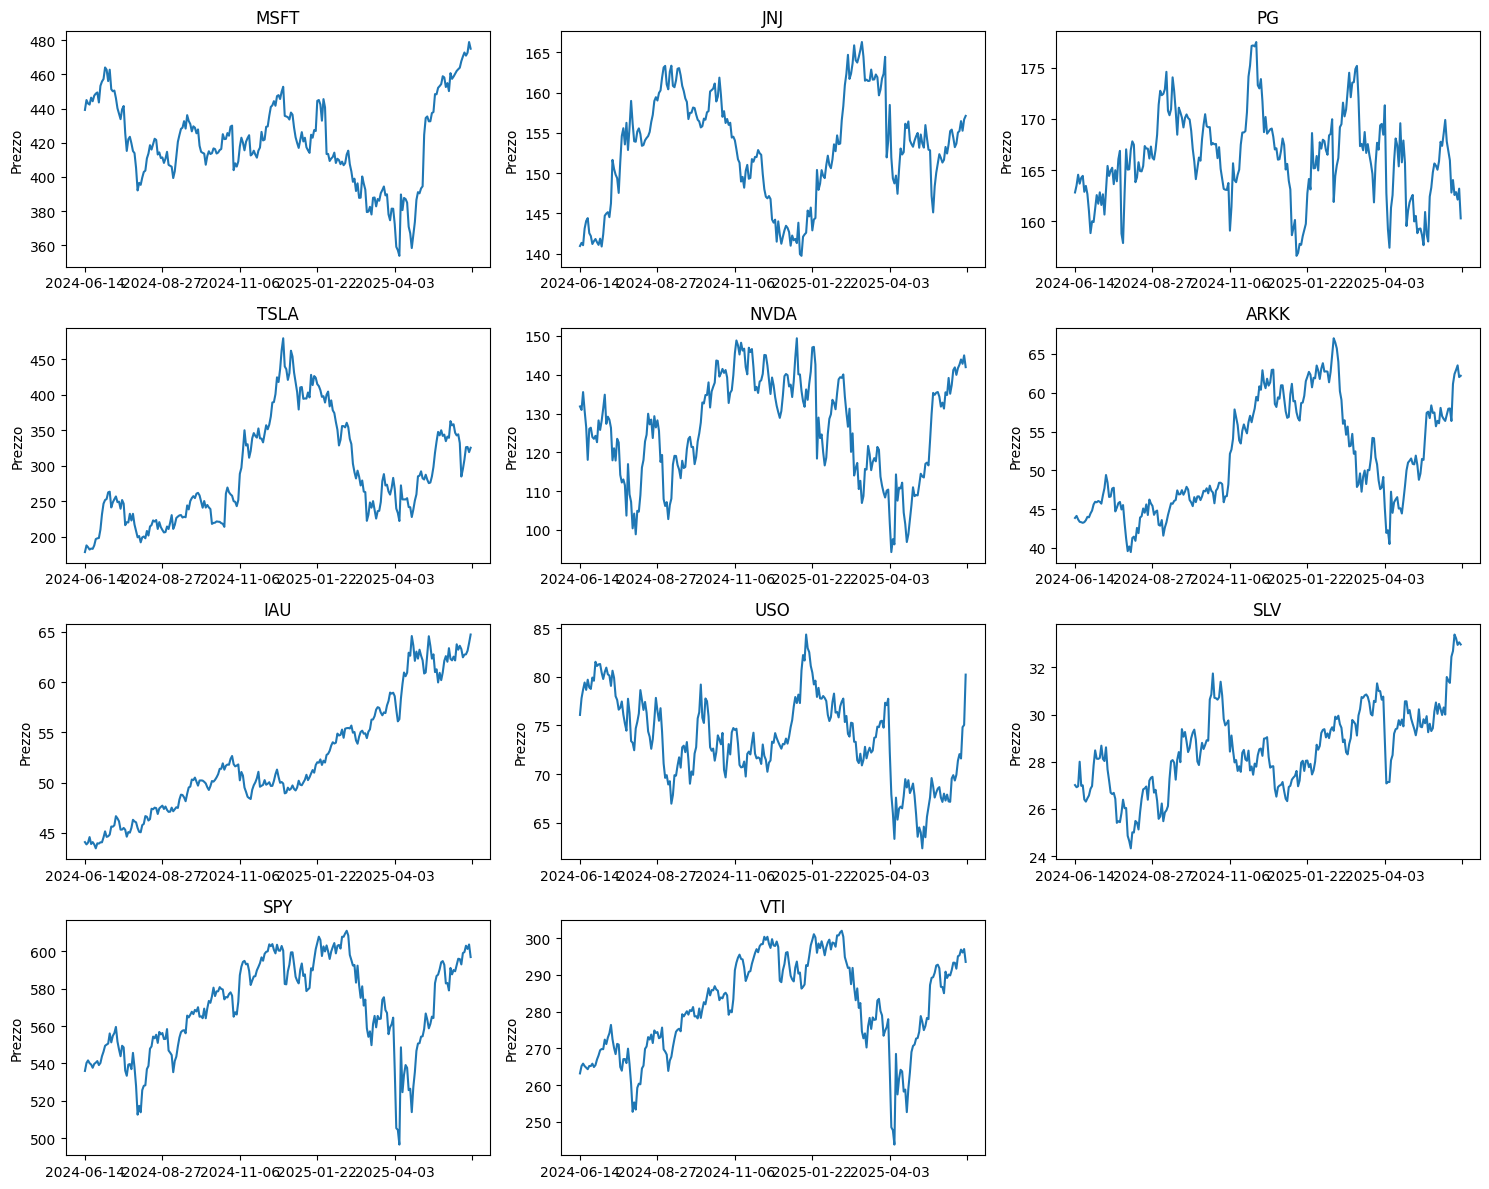

In [ ]:
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(15, 12))
axes = axes.flatten()

for i, (ticker, df2) in enumerate(dataframes.items()):
    ax = axes[i]
    df2['Close'].plot(ax=ax, title=ticker)
    ax.set_xlabel("")
    ax.set_ylabel("Prezzo")

for j in range(len(dataframes), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [ ]:
# Extract only the 'Close' column from each dataframe and rename it with the ticker
close_df2s = []
for ticker, df2 in dataframes.items():
    close_df2 = df2[['Close']].copy()
    close_df2.columns = [ticker]
    close_df2s.append(close_df2)

# Concatenate all DataFrames along the index (dates)
df2 = pd.concat(close_df2s, axis=1)

# Sort columns by ticker
df2 = df2.sort_index(axis=1)

# Print the first 5 rows
print(df2.head())

             ARKK    IAU     JNJ    MSFT    NVDA      PG    SLV     SPY  \
Price                                                                     
2024-06-14  43.87  44.08  140.95  439.20  131.84  162.81  27.01  535.96   
2024-06-17  44.13  43.85  141.34  444.96  130.94  163.50  26.92  540.22   
2024-06-18  43.68  44.03  141.05  442.94  135.54  164.54  26.96  541.60   
2024-06-20  43.37  44.58  143.12  442.31  130.74  163.67  28.00  540.13   
2024-06-21  43.32  43.89  144.06  446.36  126.53  164.24  26.98  539.40   

              TSLA    USO     VTI  
Price                              
2024-06-14  178.01  76.08  263.16  
2024-06-17  187.44  77.79  265.16  
2024-06-18  184.86  78.67  265.83  
2024-06-20  181.57  79.41  265.16  
2024-06-21  183.01  78.65  264.75  


In [ ]:
# Check for null or missing values and identify data types per column

df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 2024-06-14 to 2025-06-13
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ARKK    250 non-null    float64
 1   IAU     250 non-null    float64
 2   JNJ     250 non-null    float64
 3   MSFT    250 non-null    float64
 4   NVDA    250 non-null    float64
 5   PG      250 non-null    float64
 6   SLV     250 non-null    float64
 7   SPY     250 non-null    float64
 8   TSLA    250 non-null    float64
 9   USO     250 non-null    float64
 10  VTI     250 non-null    float64
dtypes: float64(11)
memory usage: 31.5+ KB


**1. Analysis of Financial Assets (Stocks and ETF Shares)**

We analyze the daily closing price historical series, acquired from market data, with particular attention to the shape of their distribution.

A normal distribution, with a symmetric shape centered on the mean, describes the behavior of returns over time, providing a good basis for future return forecasts. Historical series distributions that show fatter "tails" are instead indicative of extreme and anomalous events compared to average values, thus being less suitable for prediction.

**Example: The 1987 Market Crash**

On October 19, 1987, the stock market crashed about 20% in a single day. Considering a daily standard deviation of about 1%, that drop equated to roughly 20 standard deviations.

The "fatness" of the tails is usually measured through **excess kurtosis**. For a normal distribution, this value is zero; higher values indicate heavier tails, meaning a greater incidence of extreme events or "noise" compared to expected averages.

ARKK - The excess kurtosis is: 4.2333


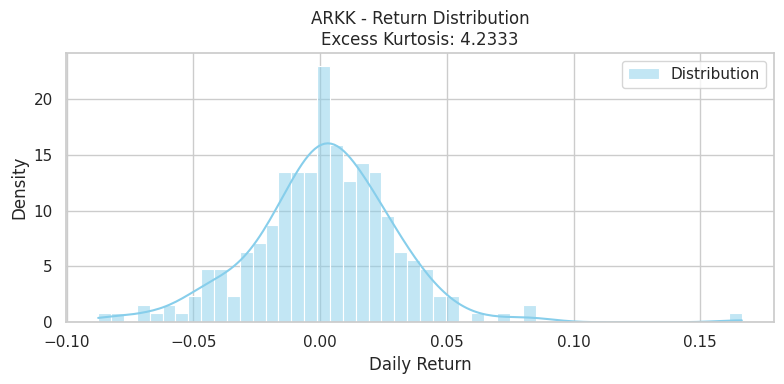

IAU - The excess kurtosis is: 0.5277


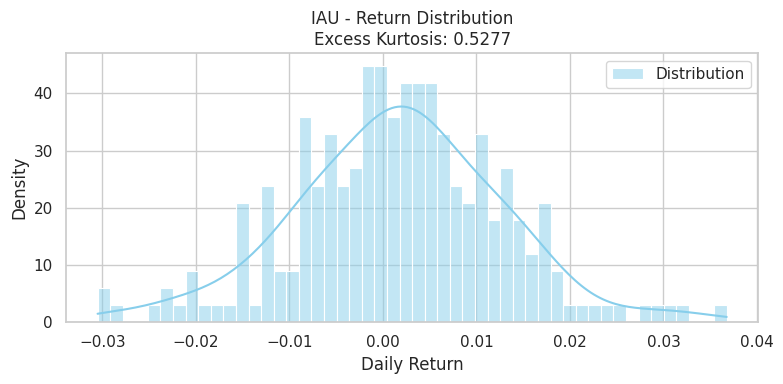

JNJ - The excess kurtosis is: 7.1225


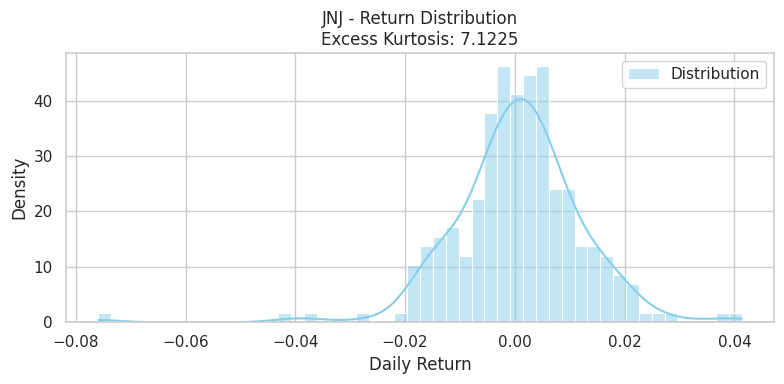

MSFT - The excess kurtosis is: 8.5313


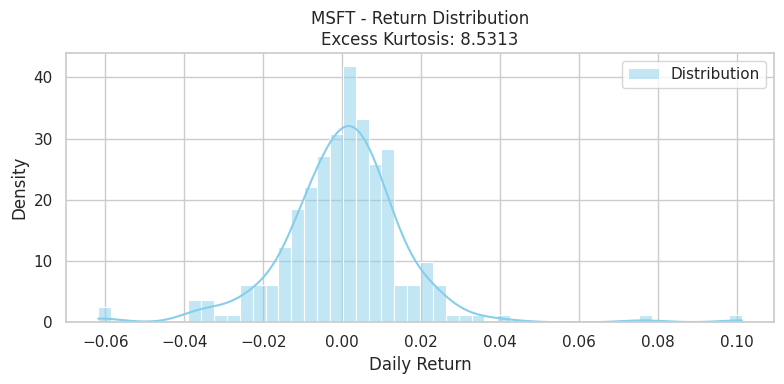

NVDA - The excess kurtosis is: 3.9283


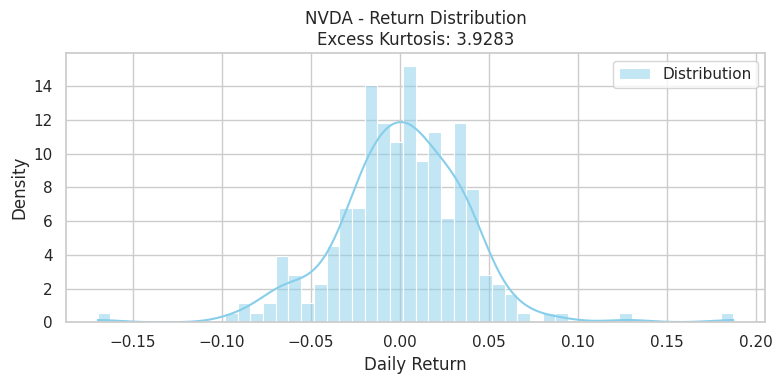

PG - The excess kurtosis is: 2.6108


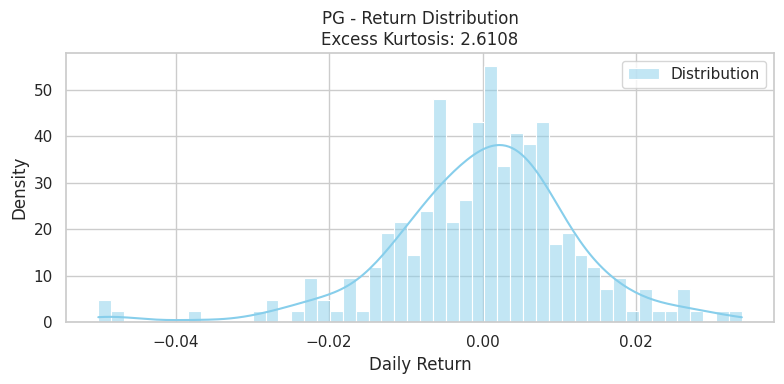

SLV - The excess kurtosis is: 1.2080


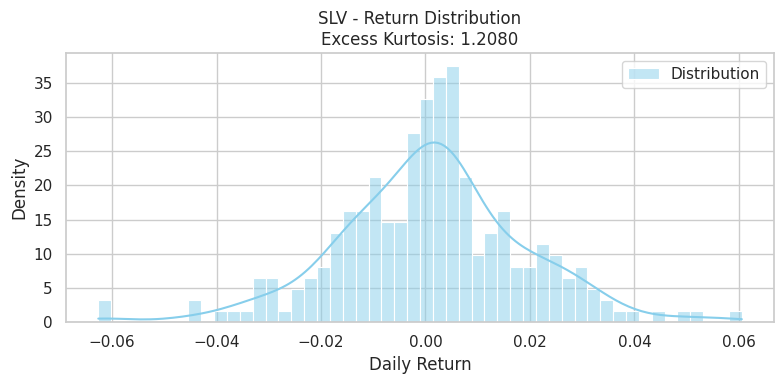

SPY - The excess kurtosis is: 18.7684


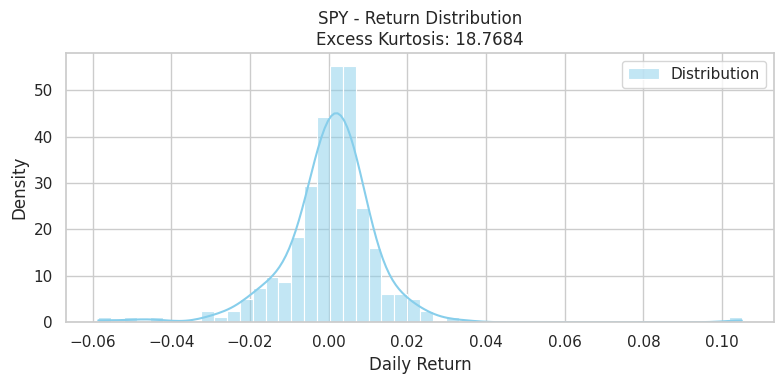

TSLA - The excess kurtosis is: 3.7149


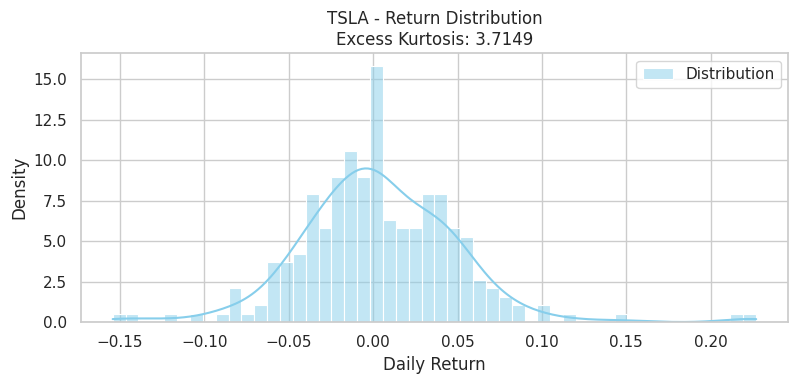

USO - The excess kurtosis is: 1.0667


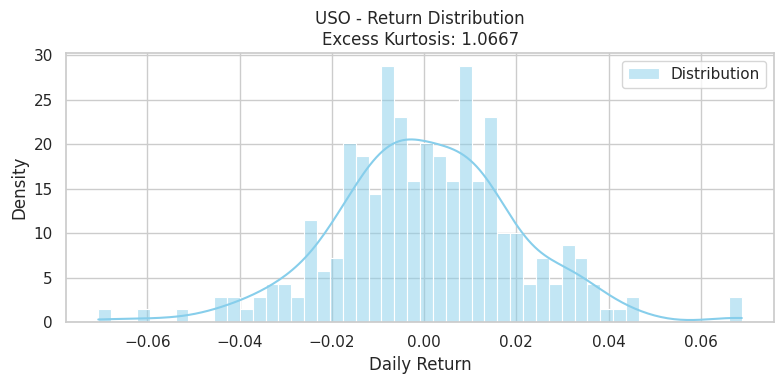

VTI - The excess kurtosis is: 16.7089


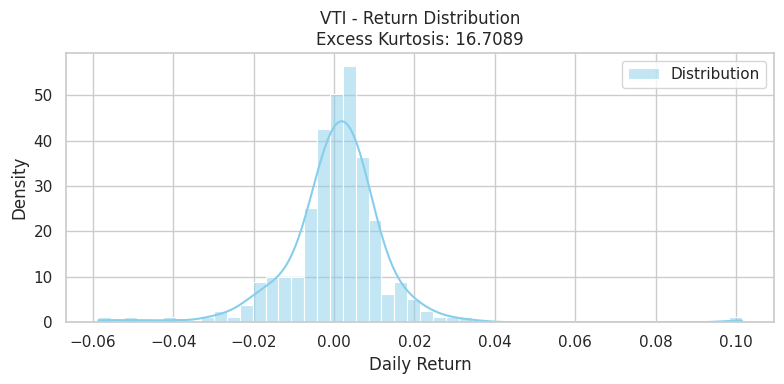

ARKK - The excess kurtosis is: 4.2333
IAU - The excess kurtosis is: 0.5277
JNJ - The excess kurtosis is: 7.1225
MSFT - The excess kurtosis is: 8.5313
NVDA - The excess kurtosis is: 3.9283
PG - The excess kurtosis is: 2.6108
SLV - The excess kurtosis is: 1.2080
SPY - The excess kurtosis is: 18.7684
TSLA - The excess kurtosis is: 3.7149
USO - The excess kurtosis is: 1.0667
VTI - The excess kurtosis is: 16.7089


In [ ]:
from scipy.stats import kurtosis

# List of tickers
tickers = ['AAPL', 'ARKK', 'IAU', 'JNJ', 'MSFT', 'NVDA', 'PG', 'SLV', 'SPY', 'TSLA', 'USO', 'VTI']

# Set Seaborn style
sns.set(style='whitegrid')

# Create a figure to plot all graphs
for ticker in tickers:
    if ticker in df2.columns:
        # Calculate daily returns
        ret = df2[ticker].pct_change().dropna()

        # Calculate kurtosis
        k = kurtosis(ret)
        print(f'{ticker} - The excess kurtosis is: {k:.4f}')

        # Plot distribution
        plt.figure(figsize=(8, 4))
        sns.histplot(ret, kde=True, bins=50, color='skyblue', stat='density', label='Distribution')
        plt.title(f'{ticker} - Return Distribution\nExcess Kurtosis: {k:.4f}')
        plt.xlabel('Daily Return')
        plt.ylabel('Density')
        plt.legend()
        plt.tight_layout()
        plt.show()

# Calculate kurtosis for each DataFrame column
for ticker in tickers:
    if ticker in df2.columns:
        ret = df2[ticker].pct_change().dropna()
        print(f'{ticker} - The excess kurtosis is: {kurtosis(ret):.4f}')

We observe that the kurtosis value is often greater than zero and, in some cases, significantly so. For this reason, we choose a method to calculate expected returns that takes into account the shape of the distribution and the possible presence of extreme events.

**Calculation of Expected Returns via Bootstrapping**

In light of the distribution analysis, instead of adopting techniques based on theoretical distributions — such as the normal distribution, which sums random price changes, or the lognormal, which multiplies random returns — we can resort to bootstrapping. This technique consists of **randomly sampling from a historical series**. Bootstrapping is not influenced by the specific time period considered, preserves the empirical distribution structure, and maintains correlations between assets.

Starting from the sampling, **we build a time series of future prices** (e.g., over 252 days) for each asset and **simulate realistic scenarios**, mitigating the impact of extreme events associated with heavy tails observed in the historical series.

In [ ]:
# Calculate daily returns
returns = df2.pct_change().dropna()

# Simulation parameters
num_sims = 1000         # number of simulations
num_days = 252          # future days to simulate: roughly one trading year
start_prices = df2.iloc[-1]  # last available prices

# Initialize a DataFrame to hold future prices
future_prices = pd.DataFrame(index=pd.bdate_range(start=pd.to_datetime(returns.index[-1]) + pd.Timedelta(days=1), periods=num_days),
                             columns=returns.columns)

# Fill the DataFrame with simulated prices for each asset
for col in returns.columns:
    # Bootstrap sample returns for this asset
    boot_returns = np.random.choice(returns[col], size=(num_days, num_sims), replace=True)

    # Create matrix of simulated prices: each column is a simulation
    boot_price_paths = np.zeros_like(boot_returns)
    boot_price_paths[0] = start_prices[col] * (1 + boot_returns[0])

    for t in range(1, num_days):
        boot_price_paths[t] = boot_price_paths[t-1] * (1 + boot_returns[t])

    # Calculate the mean across all simulations for each day
    future_prices[col] = boot_price_paths.mean(axis=1)

# Display the first days of simulated prices
print(future_prices.head())


                 ARKK        IAU         JNJ        MSFT        NVDA  \
2025-06-16  62.364870  64.828296  157.172156  475.074013  142.281605   
2025-06-17  62.584610  64.959614  157.339868  475.367554  142.473092   
2025-06-18  62.617659  65.050148  157.557904  475.578549  142.762520   
2025-06-19  62.786281  65.134811  157.752947  475.588367  143.065562   
2025-06-20  62.837022  65.237192  157.904236  475.963894  143.560972   

                    PG        SLV         SPY        TSLA        USO  \
2025-06-16  160.199776  33.006939  597.048521  326.345656  80.179154   
2025-06-17  160.219339  33.027888  597.460971  327.513396  80.195783   
2025-06-18  160.236618  33.069118  597.727533  328.741099  80.234987   
2025-06-19  160.156639  33.107402  598.547222  330.065923  80.253450   
2025-06-20  160.145627  33.117873  598.361505  331.261894  80.246664   

                   VTI  
2025-06-16  293.790683  
2025-06-17  294.079935  
2025-06-18  294.124232  
2025-06-19  294.276382  
2025-06-2

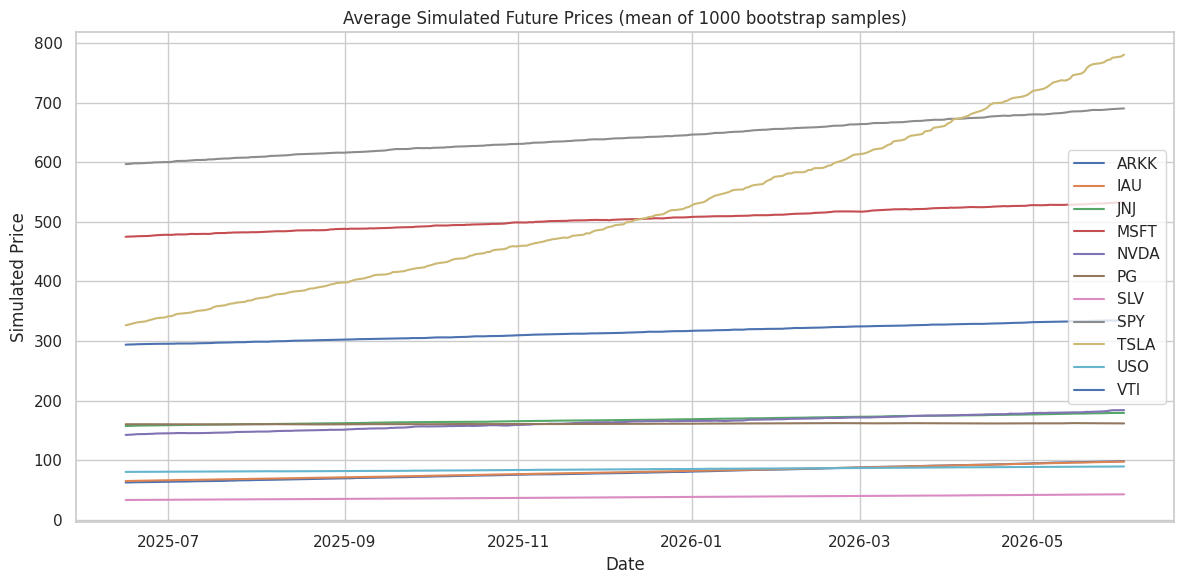

In [ ]:
# Plot of the average simulated trajectories
plt.figure(figsize=(12, 6))
for col in future_prices.columns:
    plt.plot(future_prices.index, future_prices[col], label=col)

plt.title("Average Simulated Future Prices (mean of 1000 bootstrap samples)")
plt.xlabel("Date")
plt.ylabel("Simulated Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate annualized expected return (in percentage) for each asset
annualized_returns = (future_prices.iloc[-1] / start_prices - 1) * 100
print("\nAnnualized Expected Return (percentage):")
print(annualized_returns.round(2).astype(str) + ' %')


Annualized Expected Return (percentage):
ARKK     57.79 %
IAU      50.53 %
JNJ      14.09 %
MSFT      12.2 %
NVDA      29.5 %
PG        0.83 %
SLV      28.96 %
SPY      15.68 %
TSLA    140.08 %
USO       11.3 %
VTI      14.05 %
dtype: object


**2. Identification of an Efficient Portfolio**

- Calculate the **Expected Returns** as the average of historical returns

- Calculate the **Volatility** of historical returns

- Calculate the **Covariance Matrix** among the assets

- Create **Monte Carlo Simulations** of portfolios with random weights to identify the most efficient assets and weights using the **Sharpe Ratio**

In [ ]:
# Calculate daily percentage returns
returns = df2.pct_change().dropna()

# .pct_change() calculates the percentage change between each day and the previous day
# Example: if yesterday's price was 100 and today's price is 102, the return is (102-100)/100 = 0.02 (2%)
# .dropna() removes the first row which is NaN because there is no previous price for the first day

# Display the first rows
print(returns.head())

                ARKK       IAU       JNJ      MSFT      NVDA        PG  \
Price                                                                    
2024-06-17  0.005927 -0.005218  0.002767  0.013115 -0.006826  0.004238   
2024-06-18 -0.010197  0.004105 -0.002052 -0.004540  0.035131  0.006361   
2024-06-20 -0.007097  0.012491  0.014676 -0.001422 -0.035414 -0.005287   
2024-06-21 -0.001153 -0.015478  0.006568  0.009156 -0.032201  0.003483   
2024-06-24 -0.001847  0.004329  0.002430 -0.004705 -0.066862  0.001157   

                 SLV       SPY      TSLA       USO       VTI  
Price                                                         
2024-06-17 -0.003332  0.007948  0.052975  0.022476  0.007600  
2024-06-18  0.001486  0.002555 -0.013764  0.011313  0.002527  
2024-06-20  0.038576 -0.002714 -0.017797  0.009406 -0.002520  
2024-06-21 -0.036429 -0.001352  0.007931 -0.009571 -0.001546  
2024-06-24  0.000741 -0.003244 -0.002350  0.013350 -0.001662  


In [ ]:
# Number of portfolios to simulate
num_portfolios = 5000

# Array to store results: return, volatility, sharpe ratio for each portfolio
results = np.zeros((3, num_portfolios))

# List to store weights of each simulated portfolio
weights_record = []

# Calculate annualized mean returns and covariance matrix
mean_returns = returns.mean() * 252  # 252 trading days per year
cov_matrix = returns.cov() * 252     # annualized covariance matrix

for i in range(num_portfolios):
    # Generate random weights for each asset
    weights = np.random.random(len(df2.columns))
    # Normalize weights so they sum to 1 (100% invested capital)
    weights /= np.sum(weights)

    # Save weights for later retrieval
    weights_record.append(weights)

    # Calculate expected annual portfolio return as weighted sum of mean returns
    port_return = np.dot(weights, mean_returns)

    # Calculate annualized portfolio volatility using portfolio variance formula
    port_volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))

    # Calculate Sharpe ratio (risk-adjusted return)
    # Assume risk-free rate = 0 for simplicity
    sharpe_ratio = port_return / port_volatility

    # Store calculated values in the results array
    results[0, i] = port_return
    results[1, i] = port_volatility
    results[2, i] = sharpe_ratio

# Convert results array to DataFrame for easier analysis and visualization
portfolios = pd.DataFrame(results.T, columns=['Return', 'Volatility', 'Sharpe'])

# Sort DataFrame by Sharpe Ratio in descending order and show top 5 portfolios
print(portfolios.sort_values(by='Sharpe', ascending=False).head(5))

        Return  Volatility    Sharpe
4010  0.267049    0.155625  1.715975
837   0.365564    0.214524  1.704069
4353  0.303125    0.178899  1.694393
3198  0.262910    0.155438  1.691413
2829  0.245570    0.145643  1.686111


**Selection of the optimal portfolio and visualization of results**

Optimal portfolio with maximum Sharpe Ratio:
ARKK: 14.73%
IAU: 27.71%
JNJ: 15.19%
MSFT: 6.96%
NVDA: 4.88%
PG: 14.20%
SLV: 2.90%
SPY: 6.73%
TSLA: 3.18%
USO: 1.60%
VTI: 1.92%

Expected return: 26.70%
Volatility (risk): 15.56%
Sharpe Ratio: 1.72


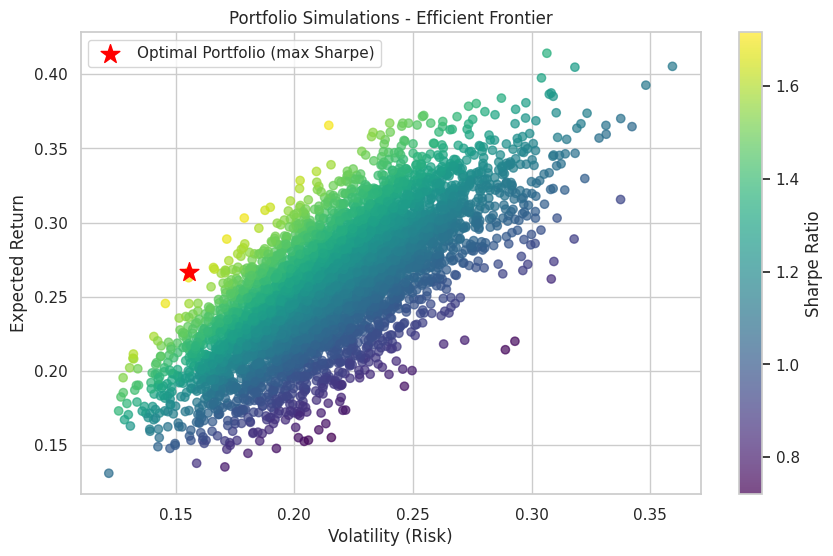

In [ ]:
# Find the index of the portfolio with the maximum Sharpe Ratio
max_sharpe_idx = portfolios['Sharpe'].idxmax()

# Optimal portfolio weights corresponding to that index
optimal_weights = weights_record[max_sharpe_idx]

print("Optimal portfolio with maximum Sharpe Ratio:")
for ticker, weight in zip(df2.columns, optimal_weights):
    print(f"{ticker}: {weight:.2%}")

print(f"\nExpected return: {portfolios.loc[max_sharpe_idx, 'Return']:.2%}")
print(f"Volatility (risk): {portfolios.loc[max_sharpe_idx, 'Volatility']:.2%}")
print(f"Sharpe Ratio: {portfolios.loc[max_sharpe_idx, 'Sharpe']:.2f}")

# Risk-return scatter plot visualization
plt.figure(figsize=(10,6))
# Scatter plot of simulated portfolios
plt.scatter(portfolios['Volatility'], portfolios['Return'], c=portfolios['Sharpe'], cmap='viridis', alpha=0.7)
plt.colorbar(label='Sharpe Ratio')

# Highlight the portfolio with maximum Sharpe Ratio
plt.scatter(portfolios.loc[max_sharpe_idx, 'Volatility'], portfolios.loc[max_sharpe_idx, 'Return'],
            color='red', marker='*', s=200, label='Optimal Portfolio (max Sharpe)')

plt.xlabel('Volatility (Risk)')
plt.ylabel('Expected Return')
plt.title('Portfolio Simulations - Efficient Frontier')
plt.legend()
plt.grid(True)
plt.show()

**MOST EFFICIENT PORTFOLIO (Highest Sharpe Ratio: 1.72)**

Based on the Monte Carlo simulations and the Sharpe ratio, the most efficient portfolio is estimated with an **expected return of 26.70%**, a **moderate volatility of 15.56%**, and an **optimal composition** that reflects a balanced allocation with a slight preference for defensive assets:

- **32,21%** of the portfolio is allocated to **safe-haven and defensive assets**, including gold (IAU), silver (SLV), and oil (USO), aiming to contain volatility and provide a hedge in unstable market conditions.

    - iShares Gold Trust (IAU): 27.71%
    - iShares Silver Trust (SLV): 2.90%
    - United States Oil Fund (USO): 1.60%

- **22.79%** is dedicated to **technology and innovation**, via exposure to high-cap growth stocks (TSLA, NVDA) and a thematic sector ETF (ARKK), supporting medium- to long-term growth potential.

    - Tesla (TSLA): 3.18%
    - NVIDIA (NVDA): 4.88%
    - ARK Innovation ETF (ARKK): 14.73%

- **37,06%** is invested in **defensive US large caps** (PG, JNJ, MSFT), to ensure stability and resilience.

    - Procter & Gamble (PG): 14.20%
    - Johnson & Johnson (JNJ): 15.19%
    - Microsoft (MSFT): 6.96%

- The remaining **8.65%** is allocated to **broad market ETFs** (SPY and VTI), benefiting from systemic diversification and portfolio efficiency.

    - SPDR S&P 500 ETF (SPY): 6.73%
    - Vanguard Total Stock Market ETF (VTI): 1.92%

**ROBO ADVISOR FOR PERSONAL FINANCE AND SAVINGS MANAGEMENT – Final Workflow**

**Building Tools and Agents with LangGraph**



Let's define the Tasks:

* Task 1: Financial analysis and savings generation
* Task 2: Analysis of the main expense items during deficit months
* Task 3: Suggestion of an efficient Investment Portfolio based on opportunity/risk ratio


In [ ]:
@tool
def analyze_finance(query: str) -> str:
    """
    Analyzes personal finances on demand.

    Supports:
    - 'monthly totals': calculates income, expenses, and monthly balance.
    - 'top 3': returns the top 3 entries by transaction type.
    - 'savings' or 'mean': calculates the average monthly savings.

    Args:
        query (str): User's question.

    Returns:
        str: Result of the requested analysis, which may be a summary of monthly totals,
             the top 3 transactions, or the average savings calculation.
    """
    query_lower = query.lower()

    if "monthly totals" in query_lower:
        monthly_summary = df.groupby(["Month", "Transaction Type"])["Amount"].sum().unstack().fillna(0)
        monthly_summary["Difference"] = monthly_summary.get("credit", 0) - monthly_summary.get("debit", 0)
        global deficit_months
        deficit_months = monthly_summary[monthly_summary["Difference"] < 0].index
        return monthly_summary.to_string(float_format="%.2f")

    elif "top 3" in query_lower:
        result = {}
        for ttype in ["debit", "credit"]:
            df_type = df[df["Transaction Type"] == ttype]
            top = (df_type.groupby(["Month", "Description"])["Amount"]
                   .sum()
                   .reset_index()
                   .sort_values(["Month", "Amount"], ascending=[True, False])
                   .groupby("Month")
                   .head(3))
            result[ttype] = top.to_string(index=False)
        return str(result)

    elif "savings" in query_lower or "mean" in query_lower:
        monthly_summary = df.groupby(["Month", "Transaction Type"])["Amount"].sum().unstack().fillna(0)
        monthly_summary["Difference"] = monthly_summary.get("credit", 0) - monthly_summary.get("debit", 0)
        avg_saving = monthly_summary["Difference"].mean()
        return f"You have saved on average {avg_saving:.2f} € per month."

    return "Unrecognized query. Try with 'monthly totals', 'top 3', or 'average savings'."

In [ ]:
@tool
def analyze_deficit_expenses(query: str) -> str:
    """
    Analyzes the 5 highest expense items in months with a negative balance.

    The query must contain the word 'deficit'.

    Returns:
        str: The top 5 monthly expense categories during deficit months.
    """
    if "deficit" not in query.lower():
        return "Invalid query for this tool."

    df_negative = df[df["Month"].isin(deficit_months) & (df["Transaction Type"] == "debit")]
    top_debits = (df_negative.groupby(["Month", "Description"])["Amount"]
                  .sum()
                  .reset_index()
                  .sort_values(["Month", "Amount"], ascending=[True, False])
                  .groupby("Month")
                  .head(5))
    return top_debits.to_string(index=False)

In [ ]:
@tool
def suggest_optimal_portfolio(df2_prices: pd.DataFrame) -> str:
    """
    Suggests an optimal balanced portfolio based on historical stock price data.

    Args:
        df2_prices (pd.DataFrame): Historical prices of selected stocks.

    Returns:
        str: Expected return, volatility, Sharpe ratio of the best portfolio + percentage weights.
    """
    returns = df2_prices.pct_change().dropna()
    mean_returns = returns.mean() * 252
    cov_matrix = returns.cov() * 252

    num_portfolios = 5000
    num_assets = len(df2_prices.columns)
    results = np.zeros((3, num_portfolios))
    weights_record = []

    for i in range(num_portfolios):
        weights = np.random.random(num_assets)
        weights /= np.sum(weights)
        weights_record.append(weights)

        port_return = np.dot(weights, mean_returns)
        port_volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
        sharpe = port_return / port_volatility

        results[0, i] = port_return
        results[1, i] = port_volatility
        results[2, i] = sharpe

    df_results = pd.DataFrame(results.T, columns=['Return', 'Volatility', 'Sharpe'])
    max_idx = df_results['Sharpe'].idxmax()
    best_portfolio = df_results.loc[max_idx]
    best_weights = weights_record[max_idx]

    composition = "\n".join(
        f"{asset}: {round(weight * 100, 2)}%"
        for asset, weight in zip(df2_prices.columns, best_weights)
    )

    return (
        f"== BEST PORTFOLIO ==\n"
        f"Expected annual return: {best_portfolio['Return']:.2%}\n"
        f"Expected volatility: {best_portfolio['Volatility']:.2%}\n"
        f"Sharpe Ratio: {best_portfolio['Sharpe']:.2f}\n\n"
        f"== SUGGESTED COMPOSITION ==\n{composition}"
    )


# Operational node
class PortfolioToolNode(Runnable):
    def invoke(self, state: AgentState, config=None, **kwargs):
        # Retrieve df2_prices from AgentState, kwargs, or fallback
        df = (
            state.get("df2_prices")
            or state.get("df2_assets")
            or kwargs.get("df2_prices")
            or kwargs.get("df2_assets")
        )

        input_dict = {"df2_prices": df}

        output = suggest_optimal_portfolio.invoke(input_dict)

        return {"query": state.get("query"), "result": output}

Agent Creation

In [ ]:
from typing import TypedDict, Literal
from langchain_core.runnables import Runnable

# AgentState e AgentDecision
class AgentState(TypedDict):
    query: str
    result: str

class AgentDecision(TypedDict):
    action: Literal["analyze_finance", "analyze_deficit_expenses", "suggest_portfolio", "end"]

Node Creation

In [ ]:
import yfinance as yf

tickers = ["AAPL", "MSFT", "JNJ", "PG", "TSLA", "NVDA", "IAU", "SLV", "USO", "SPY", "VTI", "ARKK"]
df2_azioni = yf.download(tickers, start="2020-01-01", end="2024-12-31")['Close']
df2_azioni.dropna(axis=0, inplace=True)

[*********************100%***********************]  12 of 12 completed


In [ ]:
# Operational nodes
class FinanceToolNode(Runnable):
    def invoke(self, state: AgentState, config=None, **kwargs):
        output = analyze_finance.invoke(state["query"])
        return {"query": state["query"], "result": output}

class DeficitToolNode(Runnable):
    def invoke(self, state: AgentState, config=None, **kwargs):
        output = analyze_deficit_expenses.invoke(state["query"])
        return {"query": state["query"], "result": output}

class PortfolioToolNode(Runnable):
    def invoke(self, state: AgentState, config=None, **kwargs):
        output = suggest_optimal_portfolio.invoke({"df2_prices": df2_azioni})
        return {"query": state["query"], "result": output}

# Final node
def end_node(state: AgentState):
    return {"result": f"{state.get('result', 'Nessun risultato')}"}

Decision Agent

In [ ]:
def agent_node(state: AgentState) -> AgentDecision:
    query = state["query"].lower()

    if "totals" in query:
        return {"action": "analyze_finance"}
    elif "deficit" in query:
        return {"action": "analyze_deficit_expenses"}
    elif "savings" in query or "average" in query:
        return {"action": "analyze_finance"}
    elif "portfolio" in query or "investment" in query:
        return {"action": "suggest_portfolio"}
    else:
        return {"action": "end"}

Graph Creation


In [ ]:
# Graph construction
graph = StateGraph(AgentState)
graph.add_node("agent", agent_node)
graph.add_node("analyze_finance", FinanceToolNode())
graph.add_node("analyze_deficit_expenses", DeficitToolNode())
graph.add_node("suggest_portfolio", PortfolioToolNode())
graph.add_node("end", end_node)

graph.set_entry_point("agent")
graph.add_conditional_edges("agent", lambda x: x["action"], {
    "analyze_finance": "analyze_finance",
    "analyze_deficit_expenses": "analyze_deficit_expenses",
    "suggest_portfolio": "suggest_portfolio",
    "end": "end"
})

graph.add_edge("analyze_finance", "end")
graph.add_edge("analyze_deficit_expenses", "end")
graph.add_edge("suggest_portfolio", "end")

app = graph.compile()

In [ ]:
# Display the graph structure
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except:
    # Fallback: print the graph in Mermaid format as a string
    print(app.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	agent(agent)
	analyze_finance(analyze_finance)
	analyze_deficit_expenses(analyze_deficit_expenses)
	suggest_portfolio(suggest_portfolio)
	end(end)
	__end__([<p>__end__</p>]):::last
	__start__ --> agent;
	agent -.-> analyze_deficit_expenses;
	agent -.-> analyze_finance;
	agent -.-> end;
	agent -.-> suggest_portfolio;
	analyze_deficit_expenses --> end;
	analyze_finance --> end;
	suggest_portfolio --> end;
	end --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [ ]:
# User queries
query1 = "Show me the monthly totals"
response1 = app.invoke({"query": query1})
print(f"\nQuery: {query1}")
print(response1["result"])

query2 = "Show me the deficit items"
response2 = app.invoke({"query": query2})
print(f"\nQuery: {query2}")
print(response2["result"])

query3 = "Show me the mean savings"
response3 = app.invoke({"query": query3})
print(f"\nQuery: {query3}")
print(response3["result"])

query4 = "Show me the optimal portfolio"
response4 = app.invoke({"query": query4})
print(f"\nQuery: {query4}")
print(response4["result"])


Query: Show me the monthly totals
Transaction Type  credit    debit  Difference
Month                                        
2024-01-01       7162.89  2931.45     4231.44
2024-02-01       5220.75  3165.05     2055.70
2024-03-01       7321.50  3500.16     3821.34
2024-04-01       7166.88  6029.54     1137.34
2024-05-01       5091.55 11392.03    -6300.48
2024-06-01       6017.19  3665.88     2351.31
2024-07-01       4666.34  2968.98     1697.36
2024-08-01       7379.15  2396.18     4982.97
2024-09-01       5234.71  3286.99     1947.72
2024-10-01       5022.23  2848.35     2173.88
2024-11-01       6018.96  2963.65     3055.31
2024-12-01       5635.10  3427.99     2207.11
2025-01-01       4769.44  5187.31     -417.87
2025-02-01       4500.01  3163.40     1336.61
2025-03-01       7792.25  3241.51     4550.74

Query: Show me the deficit items
     Month               Description  Amount
2024-05-01   Mike's Construction Co. 8000.00
2024-05-01          Mortgage Payment 1247.44
2024-05-01    

**CONCLUSIONS**

The project developed a **virtual assistant based on intelligent agents** for personalized financial management, capable of **monitoring income**, **expenses**, **savings**, and **monthly deficits**. Thanks to a **modular architecture** and a decision graph, the assistant can also **interpret complex requests**, offering detailed analyses and concrete suggestions. The integration of a financial agent dedicated to investment proposals, aimed at utilizing the detected savings, **guides the user throughout the entire economic management cycle**.

Overall, the system is configured as a **flexible and scalable tool**, a comprehensive virtual assistant able to support **conscious and strategic financial decisions**.